# Why is the service desk missing its SLAs?

Tidewater Logistics (fictional, about 4,200 staff) outsources IT support to a managed service provider.
The provider gets a fixed monthly fee and pays part of it back as **service credits** whenever a priority
level misses its monthly SLA target. In 2025 that happened most months.

This notebook takes the cleaned data from Postgres and works out:

1. how much the missed SLAs cost
2. what is actually causing the breaches
3. what fixing each cause would be worth

The data is simulated (see the README for how and why). The SQL behind most of these numbers is in `sql/04_analysis_queries.sql`.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats
from sqlalchemy import create_engine

sys.path.append(str(Path.cwd().parent / "src"))
import settings as cfg

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

url = "postgresql+psycopg2://{user}:{password}@{host}:{port}/{dbname}".format(
    user=os.getenv("PGUSER", cfg.PG_DEFAULTS["user"]),
    password=os.getenv("PGPASSWORD", cfg.PG_DEFAULTS["password"]),
    host=os.getenv("PGHOST", cfg.PG_DEFAULTS["host"]),
    port=os.getenv("PGPORT", cfg.PG_DEFAULTS["port"]),
    dbname=os.getenv("PGDATABASE", cfg.PG_DEFAULTS["dbname"]),
)
engine = create_engine(url)

facts = pd.read_sql("SELECT * FROM ticket_facts", engine, parse_dates=["opened_at", "opened_month"])
monthly = pd.read_sql("SELECT * FROM pbi.monthly_sla ORDER BY opened_month, priority", engine,
                      parse_dates=["opened_month"])
group_time = pd.read_sql("SELECT * FROM pbi.fact_group_time", engine)

# SLA scope: cancelled tickets and open tickets still inside target are out
scope = facts[facts["met_resolution_sla"].notna()].copy()
scope["breached"] = (~scope["met_resolution_sla"].astype(bool)).astype(int)

print(f"{len(facts):,} tickets, {len(scope):,} in SLA scope, {scope['breached'].sum():,} breaches "
      f"({scope['breached'].mean():.1%})")

42,285 tickets, 41,302 in SLA scope, 3,499 breaches (8.5%)


In [2]:
# One look for every chart: thin marks, light grid, labels in grey ink, not series colours
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
INK, INK_SOFT = "#0b0b0b", "#52514e"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#d6d5d0", "axes.labelcolor": INK_SOFT,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8,
    "xtick.color": INK_SOFT, "ytick.color": INK_SOFT,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False,
})

IMG = Path.cwd().parent / "images"
IMG.mkdir(exist_ok=True)

def save(fig, name):
    fig.savefig(IMG / name)
    plt.show()

def inr(x):
    # Indian style: 29.45 lakh rather than 2,945,000
    return f"Rs {x / 1e5:,.2f} lakh"

key = {}   # numbers the memo quotes, written to reports/key_numbers.json at the end

## 1. How much did it cost?

Resolution SLA compliance by month for each priority, against the contract target.

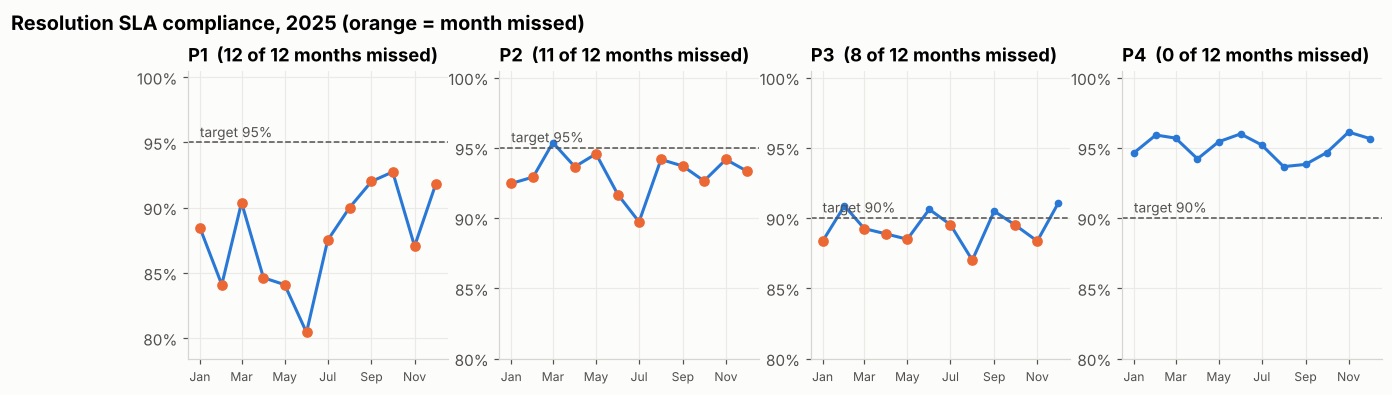

Service credits paid in 2025: Rs 29.45 lakh (about 6.5% of the year's fee)


opened_month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
priorities_missed_in_month,3,2,2,3,3,2,3,3,2,3,3,2
month_service_credit_inr,285000,190000,190000,285000,285000,190000,285000,285000,190000,285000,285000,190000


In [3]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), sharey=False)
for ax, (prio, g) in zip(axes, monthly.groupby("priority")):
    target = g["target_pct"].iloc[0]
    ax.plot(g["opened_month"], g["compliance_pct"], color=BLUE, lw=2, marker="o", ms=4)
    ax.axhline(target, color=INK_SOFT, lw=1, ls="--")
    ax.text(g["opened_month"].iloc[0], target + 0.4, f"target {target:.0f}%", color=INK_SOFT, fontsize=9)
    missed = g[g["missed_target"]]
    ax.scatter(missed["opened_month"], missed["compliance_pct"], color=ORANGE, s=36, zorder=3)
    ax.set_title(f"{prio}  ({int(g['missed_target'].sum())} of 12 months missed)")
    ax.set_ylim(min(80, g["compliance_pct"].min() - 2), 100.5)
    ax.yaxis.set_major_locator(mtick.MultipleLocator(5))
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b"))
    ax.tick_params(axis="x", labelsize=8)
fig.suptitle("Resolution SLA compliance, 2025 (orange = month missed)", x=0.01, ha="left",
             fontweight="bold", fontsize=13, y=1.04)
save(fig, "01_monthly_compliance.png")

credits = monthly.drop_duplicates("opened_month")[["opened_month", "priorities_missed_in_month", "month_service_credit_inr"]]
key["credits_total_inr"] = int(credits["month_service_credit_inr"].sum())
key["credits_avg_month_inr"] = int(credits["month_service_credit_inr"].mean())
key["months_missed"] = monthly.groupby("priority")["missed_target"].sum().astype(int).to_dict()
key["avg_compliance"] = monthly.groupby("priority")["compliance_pct"].mean().round(1).to_dict()

print(f"Service credits paid in 2025: {inr(key['credits_total_inr'])} "
      f"(about {key['credits_total_inr'] / (12 * cfg.MONTHLY_CONTRACT_FEE_INR):.1%} of the year's fee)")
credits.assign(opened_month=credits["opened_month"].dt.strftime("%b")).set_index("opened_month").T

P4 is fine. P3 hovers right on its 90% line, so small improvements there turn straight into money.
P1 and P2 miss almost every month, and they are where most of the credits come from.

P1 also has a sample size problem worth saying out loud: about 50 P1 tickets a month and a 95% target
means **three breaches in a month is already a miss**. Keep that in mind before reading too much into any single month.

In [4]:
p1_per_month = scope[scope["priority"] == "P1"].groupby("opened_month").size()
print(f"P1 tickets per month: {p1_per_month.min()} to {p1_per_month.max()}, median {p1_per_month.median():.0f}")
print(f"Breaches allowed per month at 95%: about {int(p1_per_month.median() * 0.05)}")

P1 tickets per month: 44 to 64, median 52
Breaches allowed per month at 95%: about 2


## 2. Tickets sent to the wrong team first

A "bounce" is an L2 team that had the ticket but wasn't the team that fixed it. The normal L1 to L2 handoff doesn't count.

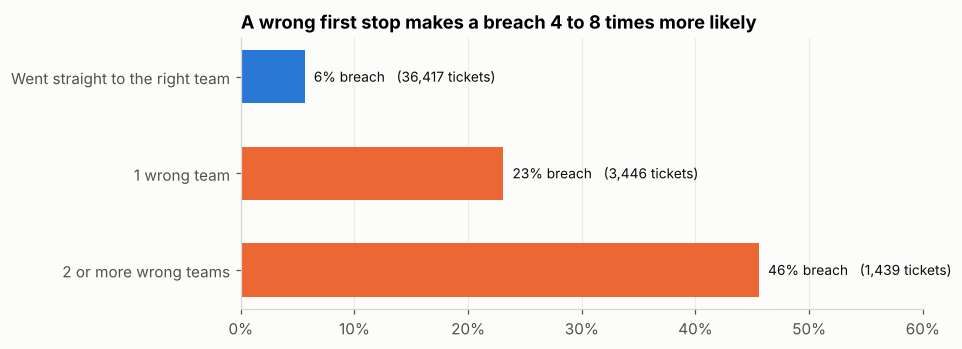

Bounced tickets are 11.8% of tickets but 41.5% of breaches.


,tickets,breach_rate,median_hours,avg_csat
Went straight to the right team,36417,0.06,6.25,4.39
1 wrong team,3446,0.23,35.06,3.67
2 or more wrong teams,1439,0.46,61.81,2.80


In [5]:
by_bounce = (scope.assign(bounces=scope["bounces"].clip(upper=2))
                  .groupby("bounces")
                  .agg(tickets=("ticket_id", "size"),
                       breach_rate=("breached", "mean"),
                       median_hours=("resolution_hours", "median"),
                       avg_csat=("csat_score", "mean")))
by_bounce.index = ["Went straight to the right team", "1 wrong team", "2 or more wrong teams"]

fig, ax = plt.subplots(figsize=(8, 3.2))
bars = ax.barh(by_bounce.index[::-1], by_bounce["breach_rate"][::-1] * 100,
               color=[ORANGE, ORANGE, BLUE], height=0.55)
for b, (_, row) in zip(bars, by_bounce[::-1].iterrows()):
    ax.text(b.get_width() + 0.8, b.get_y() + b.get_height() / 2,
            f"{row['breach_rate']:.0%} breach   ({int(row['tickets']):,} tickets)", va="center", color=INK, fontsize=9)
ax.set_xlim(0, 60)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
ax.set_title("A wrong first stop makes a breach 4 to 8 times more likely")
save(fig, "02_bounce_breach_rate.png")

bounced_share_tickets = scope["was_bounced"].mean()
bounced_share_breaches = scope.loc[scope["breached"] == 1, "was_bounced"].mean()
key["bounced_pct_tickets"] = round(bounced_share_tickets * 100, 1)
key["bounced_pct_breaches"] = round(bounced_share_breaches * 100, 1)
key["breach_rate_by_bounce"] = (by_bounce["breach_rate"] * 100).round(1).tolist()
print(f"Bounced tickets are {bounced_share_tickets:.1%} of tickets but {bounced_share_breaches:.1%} of breaches.")
by_bounce.round(2)

Is that real, or noise? Two quick tests:

- **Chi-square** on bounced vs breached (are the two independent?)
- **Mann-Whitney U** on resolution hours (resolution times are heavily skewed, so I'm not using a t-test)

In [6]:
table = pd.crosstab(scope["was_bounced"], scope["breached"])
chi2, p, dof, _ = stats.chi2_contingency(table)
n = table.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
def fmt_p(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"

print(f"Chi-square = {chi2:,.0f}, {fmt_p(p)}, Cramer's V = {cramers_v:.2f}")

# Open tickets that are already past target have no resolution time yet, so leave them out here
done = scope[scope["resolution_hours"].notna()]
u, p_u = stats.mannwhitneyu(done.loc[done["was_bounced"], "resolution_hours"],
                            done.loc[~done["was_bounced"], "resolution_hours"],
                            alternative="greater")
print(f"Mann-Whitney U: {fmt_p(p_u)} (bounced tickets take longer)")

Chi-square = 3,224, p < 0.001, Cramer's V = 0.28
Mann-Whitney U: p < 0.001 (bounced tickets take longer)


The p-values are tiny, but with 40,000 tickets almost anything is "significant". The more useful question is
whether bounced tickets are simply *harder* tickets. A slow ERP screen is a messier problem than a password reset.

So I fit a logistic regression that holds priority, subcategory, team, time of day and reopens constant,
and look at what's left for bouncing.

In [7]:
model_df = scope.assign(
    bounced=scope["was_bounced"].astype(int),
    reopened=scope["was_reopened"].astype(int),
    after_hours=scope["opened_after_hours"].astype(int),
    month_end=scope["is_month_end_window"].astype(int),
)
logit = smf.logit(
    "breached ~ bounced + reopened + after_hours + month_end + C(priority) + C(subcategory) + C(resolving_group)",
    data=model_df,
).fit(disp=False)

terms = ["bounced", "reopened", "after_hours", "month_end"]
ci = logit.conf_int().loc[terms]
odds = pd.DataFrame({
    "odds_ratio": np.exp(logit.params[terms]),
    "ci_low": np.exp(ci[0]),
    "ci_high": np.exp(ci[1]),
    "p_value": logit.pvalues[terms],
})
key["odds_bounced"] = round(float(odds.loc["bounced", "odds_ratio"]), 1)
key["odds_reopened"] = round(float(odds.loc["reopened", "odds_ratio"]), 1)
print(f"Pseudo R-squared: {logit.prsquared:.2f}")
odds.round(3)

Pseudo R-squared: 0.37


,odds_ratio,ci_low,ci_high,p_value
bounced,10.081,9.061,11.215,0.000
reopened,40.261,35.681,45.429,0.000
after_hours,1.830,1.641,2.042,0.000
month_end,1.123,1.006,1.255,0.039


Even after controlling for what the ticket is about and who fixed it, a bounce multiplies the odds of a breach
about ten times. Reopens are even worse. Being raised after hours raises the odds too (about 1.8x), but much
less than I expected at first. It makes sense once you look at the clocks: a 48-hour P3 target can absorb most of
a night. The *response* SLA is where nights really hurt (section 3).

Where do the bounces go?

In [8]:
events = pd.read_sql('''
    SELECT DISTINCT ON (ticket_id) ticket_id, assignment_group AS first_team
    FROM ticket_events
    WHERE event_type = 'Assigned' AND assignment_group <> 'Service Desk L1'
    ORDER BY ticket_id, event_time, event_id
''', engine)
paths = (scope.merge(events, on="ticket_id")
              .query("first_team != resolving_group")
              .groupby(["subcategory", "first_team", "resolving_group"])
              .agg(tickets=("ticket_id", "size"), breach_rate=("breached", "mean"))
              .sort_values("tickets", ascending=False)
              .head(10))
paths["breach_rate"] = (paths["breach_rate"] * 100).round(1)
paths

tickets  breach_rate
subcategory           first_team              resolving_group                              
Wi-Fi                 Desktop Support         Network Operations           473         27.1
WMS scanner           Desktop Support         Warehouse Systems            345         27.2
                      Network Operations      Warehouse Systems            328         21.0
Label printer         Warehouse Systems       Desktop Support              322         27.6
Something not working Collaboration Support   Desktop Support              308         49.4
                      Network Operations      Desktop Support              292         19.9
                      ERP Application Support Desktop Support              286         39.5
ERP error             Server & Cloud Ops      ERP Application Support      208         30.3
WMS error             ERP Application Support Warehouse Systems            185         36.8
VPN                   Desktop Support         Network Operations           181         22.7

In [9]:
wrong = group_time[group_time["is_wrong_team"]]
key["hours_in_wrong_queues"] = int(wrong["hours"].sum())
key["avg_hours_lost_per_bounce"] = round(float(wrong.groupby("ticket_id")["hours"].sum().mean()), 1)
print(f"Ticket-hours spent sitting with the wrong team: {key['hours_in_wrong_queues']:,}")
print(f"Average per bounced ticket: {key['avg_hours_lost_per_bounce']} hours")
print(f"Share of that time spent in a queue rather than with an agent: "
      f"{wrong.loc[wrong['state'] == 'In queue', 'hours'].sum() / wrong['hours'].sum():.0%}")

Ticket-hours spent sitting with the wrong team: 166,500
Average per bounced ticket: 34.0 hours
Share of that time spent in a queue rather than with an agent: 97%


Almost all of that time is queue time. Nobody in the wrong team is working on these tickets; they're waiting
for someone to notice they aren't theirs. That points at triage and routing rules.

## 3. The night gap

L1 works 08:00 to 20:00 on weekdays and a short Saturday. The warehouses run three shifts.

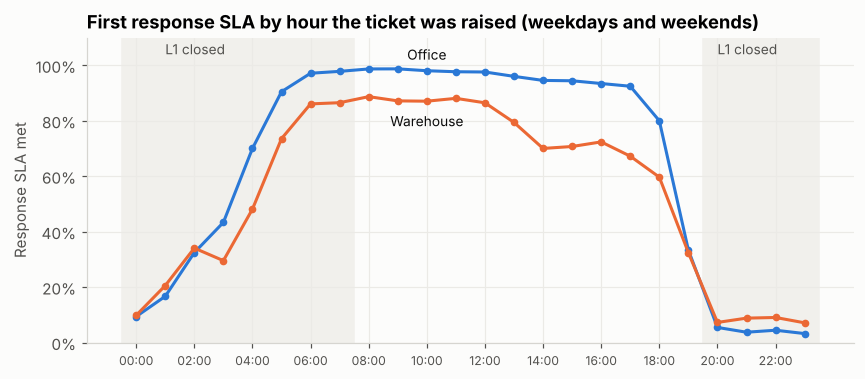

64.2% of warehouse tickets arrive while L1 is closed. Response SLA met: 33.8% vs 92.8% in hours.


In [10]:
night = (facts[facts["met_response_sla"].notna() & facts["site_type"].isin(["Office", "Warehouse"])]
         .groupby(["site_type", "opened_hour"])["met_response_sla"].mean().mul(100).unstack(0))

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.axvspan(-0.5, 7.5, color="#f1f0ec", zorder=0)
ax.axvspan(19.5, 23.5, color="#f1f0ec", zorder=0)
ax.plot(night.index, night["Office"], color=BLUE, lw=2, marker="o", ms=4)
ax.plot(night.index, night["Warehouse"], color=ORANGE, lw=2, marker="o", ms=4)
ax.text(10, night.loc[10, "Office"] + 4, "Office", color=INK, ha="center", fontsize=9)
ax.text(10, night.loc[10, "Warehouse"] - 9, "Warehouse", color=INK, ha="center", fontsize=9)
ax.text(1, 104, "L1 closed", color=INK_SOFT, fontsize=9)
ax.text(20, 104, "L1 closed", color=INK_SOFT, fontsize=9)
ax.set_xticks(range(0, 24, 2))
ax.set_xticklabels([f"{h:02d}:00" for h in range(0, 24, 2)], fontsize=8)
ax.set_ylim(0, 110)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylabel("Response SLA met")
ax.set_title("First response SLA by hour the ticket was raised (weekdays and weekends)")
save(fig, "03_night_gap.png")

wh = facts[(facts["site_type"] == "Warehouse") & facts["met_response_sla"].notna()]
key["warehouse_after_hours_share"] = round(wh["opened_after_hours"].mean() * 100, 1)
key["warehouse_after_hours_response_met"] = round(wh.loc[wh["opened_after_hours"], "met_response_sla"].mean() * 100, 1)
key["warehouse_in_hours_response_met"] = round(wh.loc[~wh["opened_after_hours"], "met_response_sla"].mean() * 100, 1)
print(f"{key['warehouse_after_hours_share']}% of warehouse tickets arrive while L1 is closed. "
      f"Response SLA met: {key['warehouse_after_hours_response_met']}% vs {key['warehouse_in_hours_response_met']}% in hours.")

In [11]:
lockouts = facts[(facts["site_type"] == "Warehouse") & facts["opened_after_hours"]
                 & facts["subcategory"].isin(["Password reset", "Account lockout"])
                 & facts["resolution_hours"].notna()]
key["night_lockouts"] = len(lockouts)
key["night_lockout_median_hours"] = round(float(lockouts["resolution_hours"].median()), 1)
key["night_lockout_worker_hours"] = int(lockouts["resolution_hours"].sum())
print(f"{len(lockouts):,} warehouse lockouts and password resets were raised while L1 was closed.")
print(f"Median wait for a fix: {key['night_lockout_median_hours']} hours. "
      f"Total waiting: {key['night_lockout_worker_hours']:,} person-hours.")

1,416 warehouse lockouts and password resets were raised while L1 was closed.
Median wait for a fix: 9.6 hours. Total waiting: 19,547 person-hours.


A picker who's locked out of the handheld at 23:00 waits until L1 logs in at 08:00. That is a 10-minute fix
that costs most of a shift. In practice a supervisor probably moves that person to another task or lends a
device, so the person-hours above are an **upper bound** on lost work, not a measured loss.

Volume by weekday and hour, to see the Monday pile-up:

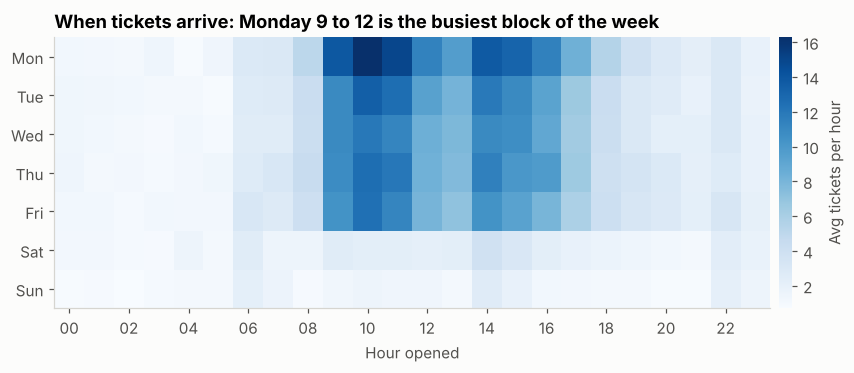

Monday volume is 1.49x the Tue-Fri average.


In [12]:
human = facts[(facts["channel"] != "Monitoring") & (facts["status"] != "Cancelled")]
days_per_weekday = human.groupby("opened_isodow")["opened_date"].nunique()
heat = human.groupby(["opened_isodow", "opened_hour"]).size().unstack(fill_value=0)
heat = heat.div(days_per_weekday, axis=0)   # average tickets per hour on that weekday

fig, ax = plt.subplots(figsize=(10, 3.2))
im = ax.imshow(heat.values, aspect="auto", cmap="Blues")
ax.set_yticks(range(7))
ax.set_yticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_xticks(range(0, 24, 2))
ax.set_xticklabels([f"{h:02d}" for h in range(0, 24, 2)])
ax.grid(False)
ax.set_xlabel("Hour opened")
cb = fig.colorbar(im, ax=ax, pad=0.01)
cb.set_label("Avg tickets per hour", color=INK_SOFT)
cb.outline.set_visible(False)
ax.set_title("When tickets arrive: Monday 9 to 12 is the busiest block of the week")
save(fig, "04_weekday_heatmap.png")

per_day = human.groupby("opened_isodow").size() / days_per_weekday
key["monday_vs_midweek"] = round(float(per_day[1] / per_day[2:6].mean()), 2)
print(f"Monday volume is {key['monday_vs_midweek']}x the Tue-Fri average.")

## 4. Reopens

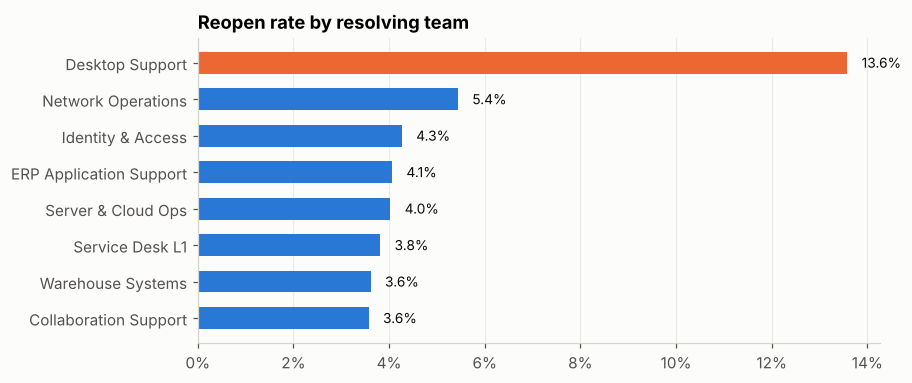

P1/P2 tickets that get reopened breach 98.4% of the time.
75.8% of all P2 breaches are reopened tickets.


In [13]:
resolved = facts[facts["resolved_at"].notna()]
reopen = (resolved.groupby("resolving_group")["was_reopened"].mean().mul(100)
                  .sort_values())

fig, ax = plt.subplots(figsize=(8, 3.6))
colors = [ORANGE if g == "Desktop Support" else BLUE for g in reopen.index]
bars = ax.barh(reopen.index, reopen.values, color=colors, height=0.6)
for b, v in zip(bars, reopen.values):
    ax.text(v + 0.3, b.get_y() + b.get_height() / 2, f"{v:.1f}%", va="center", fontsize=9, color=INK)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
ax.set_title("Reopen rate by resolving team")
save(fig, "05_reopen_by_team.png")

key["desktop_reopen_pct"] = round(float(reopen["Desktop Support"]), 1)
key["others_reopen_pct"] = round(float(resolved.loc[resolved["resolving_group"] != "Desktop Support", "was_reopened"].mean() * 100), 1)

hp = scope[scope["priority"].isin(["P1", "P2"])]
key["p1p2_breach_when_reopened"] = round(float(hp.loc[hp["was_reopened"], "breached"].mean() * 100), 1)
key["p2_breaches_from_reopens_pct"] = round(float(
    scope[(scope["priority"] == "P2") & (scope["breached"] == 1)]["was_reopened"].mean() * 100), 1)
print(f"P1/P2 tickets that get reopened breach {key['p1p2_breach_when_reopened']}% of the time.")
print(f"{key['p2_breaches_from_reopens_pct']}% of all P2 breaches are reopened tickets.")

That P1/P2 line is the most useful single finding here. The contract measures resolution to the *final* fix,
so a P2 that gets "resolved" early and comes back a day later has already blown its 8-hour clock.
Closing a P1 or P2 without the user confirming it works is close to a guaranteed breach.

Is Desktop Support's reopen rate a few people, or the whole team?

In [14]:
ds = resolved[resolved["resolving_group"] == "Desktop Support"]
agent_table = pd.crosstab(ds["assigned_to"], ds["was_reopened"])
chi2, p, dof, _ = stats.chi2_contingency(agent_table)
rates = (agent_table[True] / agent_table.sum(axis=1) * 100).sort_values()
print(f"Agent reopen rates range from {rates.min():.1f}% to {rates.max():.1f}%")
print(f"Chi-square across {len(rates)} agents: p = {p:.2f}")
key["ds_agent_reopen_range"] = [round(float(rates.min()), 1), round(float(rates.max()), 1)]
key["ds_agent_p_value"] = round(float(p), 2)

Agent reopen rates range from 11.2% to 14.7%
Chi-square across 9 agents: p = 0.41


No agent stands out (p well above 0.05). Every engineer in the team reopens at about the same rate,
which points at the team's closing step. Coaching one person won't fix it. Changing the
closure step will (call or message the user, get a "yes it works", then resolve).

## 5. The VPN client rollout

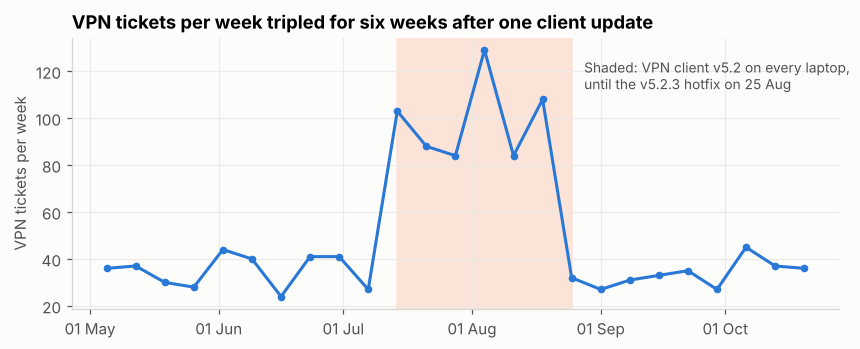

Extra VPN tickets caused by the rollout: about 389
Network Ops breach rate on NON-VPN tickets: {'after': 6.7, 'before': 7.8, 'during': 10.2}


In [15]:
weekly = (facts[facts["status"] != "Cancelled"]
          .set_index("opened_at").sort_index()
          .loc["2025-05-05":"2025-10-26"]
          .assign(vpn=lambda d: (d["subcategory"] == "VPN").astype(int))
          .resample("W-MON", label="left", closed="left")["vpn"].sum())

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.axvspan(cfg.VPN_INCIDENT_START, cfg.VPN_INCIDENT_END, color="#fbe3d8", zorder=0)
ax.plot(weekly.index, weekly.values, color=BLUE, lw=2, marker="o", ms=4)
ax.text(cfg.VPN_INCIDENT_END + pd.Timedelta(days=3), weekly.max() * 0.97,
        "Shaded: VPN client v5.2 on every laptop,\nuntil the v5.2.3 hotfix on 25 Aug", color=INK_SOFT, fontsize=9, va="top")
ax.set_ylabel("VPN tickets per week")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d %b"))
ax.set_title("VPN tickets per week tripled for six weeks after one client update")
save(fig, "06_vpn_incident.png")

phase = np.select([facts["opened_at"] < cfg.VPN_INCIDENT_START, facts["opened_at"] < cfg.VPN_INCIDENT_END],
                  ["before", "during"], "after")
f2 = facts.assign(phase=phase)
f2 = f2[f2["status"] != "Cancelled"]
vpn_per_day = f2[f2["subcategory"] == "VPN"].groupby("phase").size() / f2.groupby("phase")["opened_date"].nunique()
normal_rate = vpn_per_day[["before", "after"]].mean()
incident_days = (cfg.VPN_INCIDENT_END - cfg.VPN_INCIDENT_START).days
key["vpn_extra_tickets"] = int(round((vpn_per_day["during"] - normal_rate) * incident_days))
key["vpn_per_day"] = vpn_per_day.round(1).to_dict()
netops = scope[scope["resolving_group"] == "Network Operations"].assign(
    phase=lambda d: np.select([d["opened_at"] < cfg.VPN_INCIDENT_START, d["opened_at"] < cfg.VPN_INCIDENT_END],
                              ["before", "during"], "after"))
key["netops_non_vpn_breach"] = (netops[netops["subcategory"] != "VPN"].groupby("phase")["breached"].mean() * 100).round(1).to_dict()
print(f"Extra VPN tickets caused by the rollout: about {key['vpn_extra_tickets']}")
print("Network Ops breach rate on NON-VPN tickets:", key["netops_non_vpn_breach"])

The VPN tickets were only part of the damage. Network Ops was buried, so their other tickets (Wi-Fi, site
outages, slow network) breached more often too. A pilot group of 50 to 100 laptops for a week before a
company-wide push would likely have caught this.

## 6. Month end

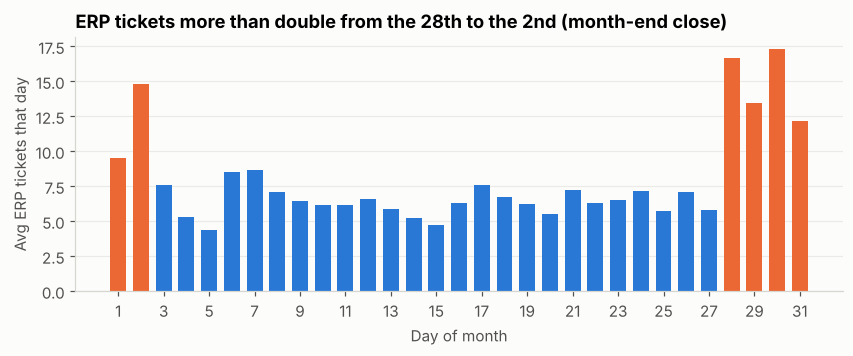

Month-end ERP volume is 2.2x the rest of the month


In [16]:
erp = facts[facts["subcategory"].isin(["ERP error", "ERP performance"])]
erp_day = erp.groupby(erp["opened_at"].dt.day).size() / erp.groupby(erp["opened_at"].dt.day)["opened_month"].nunique()

fig, ax = plt.subplots(figsize=(9, 3))
colors = [ORANGE if (d >= 28 or d <= 2) else BLUE for d in erp_day.index]
ax.bar(erp_day.index, erp_day.values, color=colors, width=0.7)
ax.set_xticks(range(1, 32, 2))
ax.set_xlabel("Day of month")
ax.set_ylabel("Avg ERP tickets that day")
ax.grid(axis="x", visible=False)
ax.set_title("ERP tickets more than double from the 28th to the 2nd (month-end close)")
save(fig, "07_month_end_erp.png")

key["erp_month_end_multiplier"] = round(float(
    erp_day[(erp_day.index >= 28) | (erp_day.index <= 2)].mean() / erp_day[(erp_day.index > 2) & (erp_day.index < 28)].mean()), 1)
print(f"Month-end ERP volume is {key['erp_month_end_multiplier']}x the rest of the month")

ERP Application Support has 6 people and works Mon to Fri. Moving one or two engineers' leave and
training away from the last three days of the month costs nothing.

## 7. What fixing it is worth

Service credits are a step function (a priority either clears its target in a month or it doesn't), so I
re-score every month under each scenario rather than multiplying an average.

How each scenario changes a ticket's breach chance:

- **Fix routing:** half of the bounced tickets in the grey-area subcategories go straight to the right team.
  Those tickets get the breach rate of direct tickets with the same priority and subcategory.
- **Confirm before closing:** half of all reopens don't happen, because the user is asked to confirm before
  the ticket is resolved. Those tickets get the breach rate of non-reopened tickets with the same priority and subcategory.

"Half" is my assumption. It's deliberately not 100%; no process change removes every bounce.

In [17]:
GREY_AREA = ["Wi-Fi", "WMS scanner", "WMS error", "Label printer", "Something not working",
             "ERP error", "ERP performance", "VPN", "Slow network", "New access request"]
targets = {p: v[2] for p, v in cfg.SLA_POLICY.items()}
keys = list(zip(scope["priority"], scope["subcategory"]))

def rate_lookup(mask):
    r = scope[mask].groupby(["priority", "subcategory"])["breached"].mean()
    return np.array([r.get(k, 0.0) for k in keys])

direct_rate = rate_lookup(~scope["was_bounced"])
clean_rate = rate_lookup(~scope["was_reopened"])
actual = scope["breached"].to_numpy(dtype=float)

def apply_routing(expected, share=0.5):
    m = (scope["was_bounced"] & scope["subcategory"].isin(GREY_AREA)).to_numpy()
    return np.where(m, (1 - share) * expected + share * direct_rate, expected)

def apply_confirmation(expected, share=0.5):
    m = scope["was_reopened"].to_numpy()
    return np.where(m, (1 - share) * expected + share * clean_rate, expected)

def score(expected):
    g = (scope.assign(expected=expected)
              .groupby(["opened_month", "priority"])
              .agg(n=("expected", "size"), breaches=("expected", "sum"))
              .reset_index())
    g["compliance"] = 100 * (1 - g["breaches"] / g["n"])
    g["missed"] = g["compliance"] < g["priority"].map(targets)
    per_month = g.groupby("opened_month")["missed"].sum()
    credit = (np.minimum(cfg.SERVICE_CREDIT_CAP_PCT, cfg.SERVICE_CREDIT_PER_MISS_PCT * per_month)
              / 100 * cfg.MONTHLY_CONTRACT_FEE_INR).sum()
    row = {"credits_inr": int(round(credit))}
    row.update({f"{p}_months_missed": int(v) for p, v in g.groupby("priority")["missed"].sum().items()})
    return row

scenarios = pd.DataFrame({
    "As it was": score(actual),
    "Fix routing": score(apply_routing(actual)),
    "Confirm before closing": score(apply_confirmation(actual)),
    "Both": score(apply_confirmation(apply_routing(actual))),
}).T
scenarios["saving_inr"] = scenarios.loc["As it was", "credits_inr"] - scenarios["credits_inr"]

# Sanity check: "As it was" must match the SQL view exactly, or the scoring logic is wrong
assert scenarios.loc["As it was", "credits_inr"] == key["credits_total_inr"], "scenario scoring doesn't match SQL"

key["scenarios"] = scenarios.astype(int).to_dict(orient="index")
scenarios

,credits_inr,P1_months_missed,P2_months_missed,P3_months_missed,P4_months_missed,saving_inr
As it was,2945000,12,11,8,0,0
Fix routing,2565000,12,11,4,0,380000
Confirm before closing,1520000,12,2,2,0,1425000
Both,1330000,12,2,0,0,1615000


Both fixes together cut credits by more than half. The confirmation step is the bigger lever by far,
because reopens are what sink P2. Routing on its own saves less, but it's what gets P3 over its line in the
months where the confirmation step alone isn't enough.

**P1 doesn't move in any scenario, and I don't think it can with process changes alone.** Even P1 tickets that
went straight to the right team and were never reopened breach more than 5% of the time. With about 50
P1s a month, the 95% target leaves room for two breaches. The next step there is to sit with Network Ops and
look at the site-down tickets one by one: if most were waiting on the telecom carrier, the fix is a
back-to-back SLA with the carrier or a second link at the warehouses, and that's a conversation the ticket data
alone can't settle.

In [18]:
clean_p1 = scope[(scope["priority"] == "P1") & ~scope["was_bounced"] & ~scope["was_reopened"]]
key["p1_clean_breach_pct"] = round(float(clean_p1["breached"].mean() * 100), 1)
print(f"P1 tickets with no bounce and no reopen still breach {key['p1_clean_breach_pct']}% of the time")
scope[scope["priority"] == "P1"].groupby("subcategory").agg(
    tickets=("ticket_id", "size"), breaches=("breached", "sum")).sort_values("breaches", ascending=False).head(5)

P1 tickets with no bounce and no reopen still breach 6.3% of the time


,tickets,breaches
subcategory,,
Site down,237,28
ERP error,38,11
WMS error,85,10
VM down,121,8
ERP performance,16,7


### Self-service password reset

Password resets and lockouts are cheap for L1 (about 10 minutes each), so the L1 saving is small.
The bigger effect is on the warehouse night shift.

In [19]:
resets = facts[facts["subcategory"].isin(["Password reset", "Account lockout"]) & (facts["status"] != "Cancelled")]
l1_hours = resets["work_minutes"].sum() / 60
saved_hours = l1_hours * cfg.SSPR_ADOPTION
key["reset_tickets"] = len(resets)
key["reset_pct_of_tickets"] = round(len(resets) / (facts["status"] != "Cancelled").sum() * 100, 1)
key["sspr_l1_hours_saved"] = int(saved_hours)
key["sspr_l1_fte_saved"] = round(saved_hours / cfg.PRODUCTIVE_HOURS_PER_FTE_YEAR, 2)
key["sspr_l1_cost_saved_inr"] = int(saved_hours * cfg.L1_COST_PER_HOUR_INR)
key["sspr_warehouse_hours_recovered"] = int(key["night_lockout_worker_hours"] * cfg.SSPR_ADOPTION)
key["sspr_warehouse_value_inr"] = int(key["sspr_warehouse_hours_recovered"] * cfg.WAREHOUSE_WORKER_COST_PER_HOUR_INR)

print(f"Reset/lockout tickets: {len(resets):,} ({key['reset_pct_of_tickets']}% of all tickets)")
print(f"L1 time saved at {cfg.SSPR_ADOPTION:.0%} adoption: {saved_hours:,.0f} hours "
      f"= {key['sspr_l1_fte_saved']} FTE = {inr(key['sspr_l1_cost_saved_inr'])} a year")
print(f"Warehouse waiting time removed (upper bound): {key['sspr_warehouse_hours_recovered']:,} hours "
      f"= {inr(key['sspr_warehouse_value_inr'])} at Rs {cfg.WAREHOUSE_WORKER_COST_PER_HOUR_INR}/hour")

Reset/lockout tickets: 7,527 (18.2% of all tickets)
L1 time saved at 70% adoption: 1,049 hours = 0.55 FTE = Rs 4.40 lakh a year
Warehouse waiting time removed (upper bound): 13,682 hours = Rs 15.05 lakh at Rs 110/hour


### Night cover at L1

What would one L1 agent on nights (20:00 to 08:00, every day) cost?

In [20]:
night_hours = 12 * 365
night_cost = night_hours * cfg.L1_COST_PER_HOUR_INR * cfg.NIGHT_SHIFT_PREMIUM
after_hours = facts[facts["opened_after_hours"] & (facts["status"] != "Cancelled")]
nights_per_year = after_hours["opened_date"].nunique()
key["night_cover_cost_inr"] = int(night_cost)
key["after_hours_tickets"] = len(after_hours)
key["after_hours_per_night"] = round(len(after_hours) / nights_per_year, 1)
print(f"Night seat: {night_hours:,} hours a year (about {night_hours / cfg.PRODUCTIVE_HOURS_PER_FTE_YEAR:.1f} people on rotation), "
      f"{inr(night_cost)} a year")
print(f"After-hours tickets: {len(after_hours):,} a year, about {key['after_hours_per_night']} per night")

Night seat: 4,380 hours a year (about 2.3 people on rotation), Rs 21.16 lakh a year
After-hours tickets: 9,159 a year, about 25.1 per night


Most of the night problem lands on the *response* SLA, and this contract only charges credits on *resolution*.
Nights do raise resolution breach odds a little (about 1.8x in the regression), but I haven't modelled how many
credits a night seat would save, and I'd expect it to be well short of the seat's cost. So night cover is mainly a
service-quality decision for the client.
I'd do self-service reset first (it removes the most painful night tickets for very little money) and only then
look at whether the remaining night volume justifies a seat.

In [21]:
out = Path.cwd().parent / "reports" / "key_numbers.json"
out.write_text(json.dumps(key, indent=2, default=str))
print(f"Wrote {len(key)} numbers to {out.name}")

Wrote 40 numbers to key_numbers.json
